# 4. A future system: Holistic Transition, 2040

NESO's Future Energy Scenarios (FES) describe how Great Britain's energy system could reach net zero, as a set of
pathways with capacity and demand for every year to 2050. This tutorial builds FES 2025's Holistic Transition pathway
for 2040 and runs the same February week as the earlier tutorials, on 2013 weather, the year the CP30 and FES
long-range studies use. It then sets the 2040 week beside 2020's.

You will see:

- how a FES scenario is defined, and where its capacity comes from;
- how the fleet and the week's dispatch change between 2020 and 2040;
- what storage and hydrogen do over a week;
- how much wind and solar go unused, and what that does to prices.

The run takes 10 to 20 minutes and about 8 GB of memory.

## The scenario

```yaml
Tutorial_2040_HT_clustered:
  description: 'Tutorials: FES 2025 Holistic Transition 2040, 10-16 February on 2013 weather, ETYS clustered to GSP regions'
  targets: {source: FES, edition: 2025, pathway: HT}   # FES 2025, Holistic Transition
  method: gsp_block                     # capacity from FES building blocks, by Grid Supply Point
  modelled_year: 2040
  renewables_year: 2013                 # weather year
  demand_year: 2013                     # year of the demand shape
  network_model: ETYS
  network:
    clustering: gsp_spatial             # the full network clustered to GSP regions (tutorial 2)
  interconnectors:
    pricing:
      hourly_shape_year: 2019           # foreign prices' hourly shape (ENTSO-E data starts in 2015)
  solve_period: {enabled: true, start: 2040-02-10 00:00, end: 2040-02-16 23:00}
```

`targets` says where the numbers come from, `method` how the fleet is placed: FES publishes capacity by technology
and Grid Supply Point (GSP, where the transmission network feeds a distribution network), and each block is placed at
its GSP; transmission-connected capacity is spread within its region. Annual demand is FES's, given the hourly shape of
the demand year. The network is the 2040 ETYS network, with the reinforcements NESO plans to that year
([FES GSP blocks](../model/demand/fes_gsp_blocks.md), [generation](../model/generation/index.md)).

The [FES long-range study](../studies/fes_long_range.md) builds 2040 in more depth: demand from its parts (heat pumps,
electric vehicles, data centres), consumer flexibility, the support contracts each plant holds, and the two-stage
market. This tutorial uses the lighter standard build, which runs on a laptop.

## Run it

```bash
snakemake -j 4 --config scenario=Tutorial_2040_HT_clustered
```

For the comparison with 2020, also run `Tutorial_2020_clustered` from [tutorial 2](2-network-models.ipynb), the same
week on the same kind of network.

In [1]:
from pathlib import Path
import logging
import os
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import pypsa

logging.getLogger("pypsa").setLevel(logging.ERROR)  # keep the notebook output short
warnings.filterwarnings("ignore", message=".*GDAL.*")
warnings.filterwarnings("ignore", message=".*gdalvrt.*")

# Work from the repository root, wherever Jupyter was started.
ROOT = Path.cwd()
while not (ROOT / "Snakefile").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)

# Technology groups for charts: each PyPSA-GB carrier belongs to one group.
GROUPS = {
    "Nuclear": ["nuclear"],
    "Coal": ["coal"],
    "Gas": ["CCGT", "OCGT", "gas_engine", "CHP", "CCS Gas"],
    "Oil": ["oil"],
    "Bioenergy": ["biomass", "CCS Biomass", "biogas", "landfill_gas", "sewage_gas", "waste_to_energy",
                  "advanced_biofuel", "geothermal"],
    "Hydro": ["large_hydro", "small_hydro"],
    "Marine": ["marine", "tidal_stream", "shoreline_wave", "tidal_lagoon"],
    "Onshore wind": ["wind_onshore", "embedded_wind"],
    "Offshore wind": ["wind_offshore", "floating_wind"],
    "Solar": ["solar_pv", "embedded_solar"],
}
GROUP_OF = {carrier: group for group, carriers in GROUPS.items() for carrier in carriers}
COLOURS = {
    "Nuclear": "#6250d6", "Coal": "#4b4b4b", "Gas": "#eb6834", "Oil": "#9b6a4f", "Bioenergy": "#008300",
    "Hydro": "#5fa8d3", "Marine": "#1f9e9e", "Onshore wind": "#1baf7a", "Offshore wind": "#2a78d6",
    "Solar": "#eda100", "Hydrogen": "#e34948", "Storage": "#e87ba4", "Imports": "#9aa5a0",
}
# Consumer flexibility (EVs, heat, demand response) is built from storage units but counts as demand.
CONSUMER_FLEX = {"EV_smart_charging", "V2G_fleet", "HP_flexibility", "DH_flexibility", "SH_flexibility",
                 "IC_DSR", "residential_DSR", "DACCS"}

plt.rcParams.update({"figure.figsize": (10, 4.2), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e9e7", "legend.frameon": False, "font.size": 10})


def load(path):
    """Open a solved network, or say how to make it."""
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"{path} does not exist yet: run the scenario first (see 'Run it' above).")
    return pypsa.Network(path)


def series(n, component, attribute, names):
    """A time series for each named component; a component without one takes its static value (or zero)."""
    table = getattr(n, f"{component}_t")[attribute]
    static = getattr(n, component).get(attribute, pd.Series(0.0, index=getattr(n, component).index))
    out = table.reindex(columns=names)
    for name in out.columns[out.isna().all()]:
        out[name] = float(static.get(name, 0.0)) if attribute in ("p_set", "p_max_pu") else 0.0
    return out.fillna(0.0)


def link_output(n, names):
    """Power each link delivers at its bus1 end (MW): p0 times efficiency, so it works whether or not p1 was saved."""
    return series(n, "links", "p0", names) * n.links.efficiency.reindex(names).values


def gb_buses(n):
    """GB electricity buses (the hydrogen bus is left out)."""
    return n.buses.index[(n.buses.country == "GB") & (n.buses.carrier == "AC")]


def generation_by_group(n):
    """GB generation by technology group (MW per snapshot); hydrogen turbines are their own group."""
    gens = n.generators[n.generators.bus.isin(gb_buses(n)) & n.generators.carrier.isin(GROUP_OF)]
    out = series(n, "generators", "p", gens.index).T.groupby(gens.carrier.map(GROUP_OF)).sum().T
    turbines = n.links.index[n.links.carrier == "H2_turbine"]
    if len(turbines):
        out["Hydrogen"] = link_output(n, turbines).sum(axis=1)  # output at the electricity end
    return out[[g for g in COLOURS if g in out and out[g].abs().sum() > 0]]


def interconnectors(n):
    cc = n.links.get("counterparty_country", pd.Series("", index=n.links.index)).fillna("").astype(str)
    return n.links[(n.links.carrier == "DC") & ~cc.isin(["", "nan", "None"])]


def net_imports(n):
    """Power the interconnectors deliver into GB (MW; negative = export)."""
    ic = interconnectors(n)
    gb = set(gb_buses(n))
    flows = {}
    for name, link in ic.iterrows():
        # p0 and p1 are withdrawals at bus0 and bus1; the GB end receives minus its withdrawal.
        # Power into GB: at bus0 it is minus the flow out of bus0; at bus1 it is the link's output there.
        flows[name] = (-series(n, "links", "p0", [name])[name] if link.bus0 in gb
                       else link_output(n, [name])[name])
    return pd.DataFrame(flows, index=n.snapshots).sum(axis=1)


def grid_storage(n):
    """Net output of grid storage (MW; positive = discharging). Consumer flexibility is left out."""
    units = n.storage_units.index[~n.storage_units.carrier.isin(CONSUMER_FLEX)]
    return series(n, "storage_units", "p", units).sum(axis=1)


def gb_demand(n):
    """GB electricity demand (MW): loads, the net draw of consumer flexibility, and electrolysis."""
    loads = n.loads.index[n.loads.bus.isin(gb_buses(n))]
    demand = series(n, "loads", "p_set", loads).sum(axis=1)
    flex = n.storage_units.index[n.storage_units.carrier.isin(CONSUMER_FLEX)]
    if len(flex):
        demand = demand - series(n, "storage_units", "p", flex).sum(axis=1)
    electrolysers = n.links.index[n.links.carrier == "electrolysis"]
    if len(electrolysers):
        demand = demand + series(n, "links", "p0", electrolysers).sum(axis=1)
    return demand


def day_axis(ax):
    """Label a time axis by day: Mon 10 Feb."""
    import matplotlib.dates as mdates
    ax.xaxis.set_major_locator(mdates.DayLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b"))


def stack_plot(ax, supply, demand=None, title=None):
    """Stacked supply (GW) by group, positive above zero and negative (charging, exports) below."""
    gw = supply / 1e3
    pos, neg = gw.clip(lower=0), gw.clip(upper=0)
    ax.stackplot(gw.index, pos.T.values, colors=[COLOURS[c] for c in gw.columns], labels=gw.columns, lw=0)
    ax.stackplot(gw.index, neg.T.values, colors=[COLOURS[c] for c in gw.columns], lw=0)
    if demand is not None:
        ax.plot(demand.index, demand / 1e3, color="black", lw=1.4, label="Demand")
    ax.axhline(0, color="#555", lw=0.6)
    ax.set_ylabel("GW")
    day_axis(ax)
    if title:
        ax.set_title(title, loc="left")
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))


import geopandas as gpd
from matplotlib.collections import LineCollection

GB_OUTLINE = gpd.read_file("data/network/GSP/GSP_regions_27700_20250109.geojson").to_crs(27700).dissolve()


def network_map(ax, n, line_values=None, cmap="viridis", vmin=0, vmax=1, bus_size=6, title=None):
    """GB buses and AC lines on British National Grid coordinates (metres); lines coloured by line_values."""
    GB_OUTLINE.plot(ax=ax, color="#eef3f0", edgecolor="#c9d6cf", lw=0.4)
    buses = n.buses.loc[gb_buses(n)]
    lines = n.lines[n.lines.bus0.isin(buses.index) & n.lines.bus1.isin(buses.index)]
    segments = [[(buses.x[a], buses.y[a]), (buses.x[b], buses.y[b])] for a, b in zip(lines.bus0, lines.bus1)]
    internal = n.links[n.links.carrier.isin(["DC", "AC"]) & n.links.bus0.isin(buses.index)
                       & n.links.bus1.isin(buses.index)]
    ax.add_collection(LineCollection(
        [[(buses.x[a], buses.y[a]), (buses.x[b], buses.y[b])] for a, b in zip(internal.bus0, internal.bus1)],
        colors="#7a8f86", linewidths=0.9, linestyles="dashed"))  # links inside GB (HVDC; zonal transport links)
    if line_values is None:
        collection = LineCollection(segments, colors="#7a8f86", linewidths=0.8)
    else:
        collection = LineCollection(segments, array=line_values.reindex(lines.index).values, cmap=cmap,
                                    linewidths=1.6, norm=plt.Normalize(vmin, vmax))
    ax.add_collection(collection)
    ax.scatter(buses.x, buses.y, s=bus_size, color="#2f4f43", zorder=3)
    ax.set_xlim(-20_000, 680_000)
    ax.set_ylim(-10_000, 1_225_000)
    ax.set_aspect("equal")
    ax.set_axis_off()
    if title:
        ax.set_title(title, loc="left")
    return collection


n40 = load("resources/network/Tutorial_2040_HT_clustered_solved.nc")
path20 = Path("resources/network/Tutorial_2020_clustered_solved.nc")
n20 = pypsa.Network(path20) if path20.exists() else None
print(f"2040: {len(gb_buses(n40))} GB buses, {len(n40.generators)} generators, {len(n40.storage_units)} storage units")

2040: 293 GB buses, 5134 generators, 848 storage units


## The fleet: 2020 and 2040

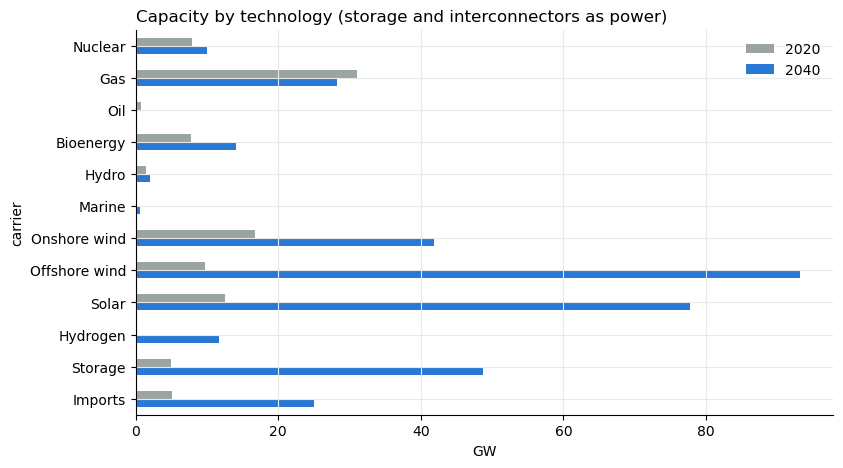

,2020,2040
carrier,,
Nuclear,7.8,10.0
Gas,31.0,28.2
Oil,0.8,0.2
Bioenergy,7.7,14.1
Hydro,1.4,1.9
Marine,0.0,0.6
Onshore wind,16.7,41.9
Offshore wind,9.7,93.2
Solar,12.6,77.7


In [2]:
def capacity(n):
    gens = n.generators[n.generators.bus.isin(gb_buses(n)) & n.generators.carrier.isin(GROUP_OF)]
    out = gens.p_nom.groupby(gens.carrier.map(GROUP_OF)).sum()
    out["Hydrogen"] = n.links.p_nom[n.links.carrier == "H2_turbine"].sum()
    out["Storage"] = n.storage_units.p_nom[~n.storage_units.carrier.isin(CONSUMER_FLEX)].sum()
    out["Imports"] = interconnectors(n).p_nom.sum()
    return out / 1e3


table = pd.DataFrame({"2040": capacity(n40)})
if n20 is not None:
    table.insert(0, "2020", capacity(n20))
table = table.reindex([g for g in COLOURS if g in table.index]).fillna(0)
table.loc["Electrolysers"] = [n.links.p_nom[n.links.carrier == "electrolysis"].sum() / 1e3
                              for n in ([n20] if n20 is not None else []) + [n40]]

ax = table.drop(index="Electrolysers").plot.barh(color=["#9aa5a0", "#2a78d6"][-len(table.columns):], figsize=(9, 5))
ax.invert_yaxis()
ax.set_xlabel("GW")
ax.set_title("Capacity by technology (storage and interconnectors as power)", loc="left")
plt.show()
table.round(1)

By 2040 the fleet is transformed. Offshore wind grows ninefold, from 10 GW to 93 GW, solar sixfold to 78 GW, and
onshore wind to 42 GW. Gas capacity barely changes, but, as the next chart shows, it hardly runs: it is kept for calm,
cold days. New are 49 GW of grid storage, 12 GW of hydrogen turbines and 7 GW of electrolysers, and the interconnectors
to other countries grow fivefold.

## The week's dispatch

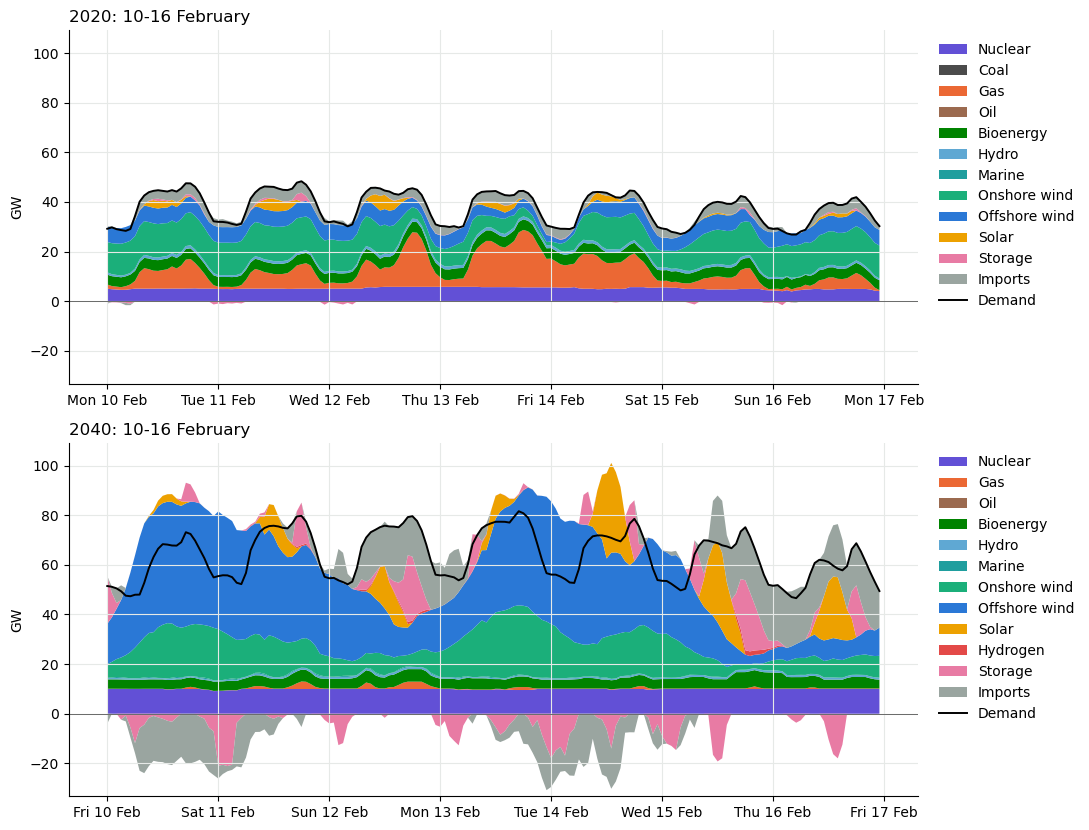

,2020,2040
carrier,,
Bioenergy,699.0,718.0
Coal,0.0,0.0
Gas,1246.0,84.0
Hydro,171.0,103.0
Hydrogen,0.0,30.0
Imports,494.0,427.0
Marine,2.0,32.0
Nuclear,870.0,1663.0
Offshore wind,916.0,4816.0


In [3]:
def supply_of(n):
    s = generation_by_group(n)
    s["Storage"] = grid_storage(n)
    s["Imports"] = net_imports(n)
    return s


runs = {"2040": n40} if n20 is None else {"2020": n20, "2040": n40}
fig, axes = plt.subplots(len(runs), 1, figsize=(11, 4.2 * len(runs)))
axes = list(axes) if len(runs) > 1 else [axes]
top = max(supply_of(n).clip(lower=0).sum(axis=1).max() for n in runs.values()) / 1e3 * 1.08
bottom = min(supply_of(n).clip(upper=0).sum(axis=1).min() for n in runs.values()) / 1e3 * 1.08
for ax, (year, n) in zip(axes, runs.items()):
    stack_plot(ax, supply_of(n), gb_demand(n), title=f"{year}: 10-16 February")
    ax.set_ylim(bottom, top)
plt.tight_layout()
plt.show()

pd.DataFrame({year: supply_of(n).sum() / 1e3 for year, n in runs.items()}).round(0).fillna(0)

In the same week of 2040, wind and solar supply more than GB uses on the windy days, 10 and 11 February and 13
and 14 February. The surplus goes abroad (grey, below zero) and into storage (pink). On the calmer days, from the
afternoon of 11 February and on 15 and 16 February, storage and imports fill the gap, and over the week GB imports
more than it exports. Gas runs for 84 GWh over the week, against 1,246 GWh in 2020; nuclear runs flat.

## Storage and hydrogen

Batteries and long-duration storage shift energy by hours to days. The hydrogen system shifts it further:
electrolysers make hydrogen when power is cheap, a store holds it, and hydrogen turbines turn it back into electricity
when wind is low ([flexibility](../model/flexibility/index.md)).

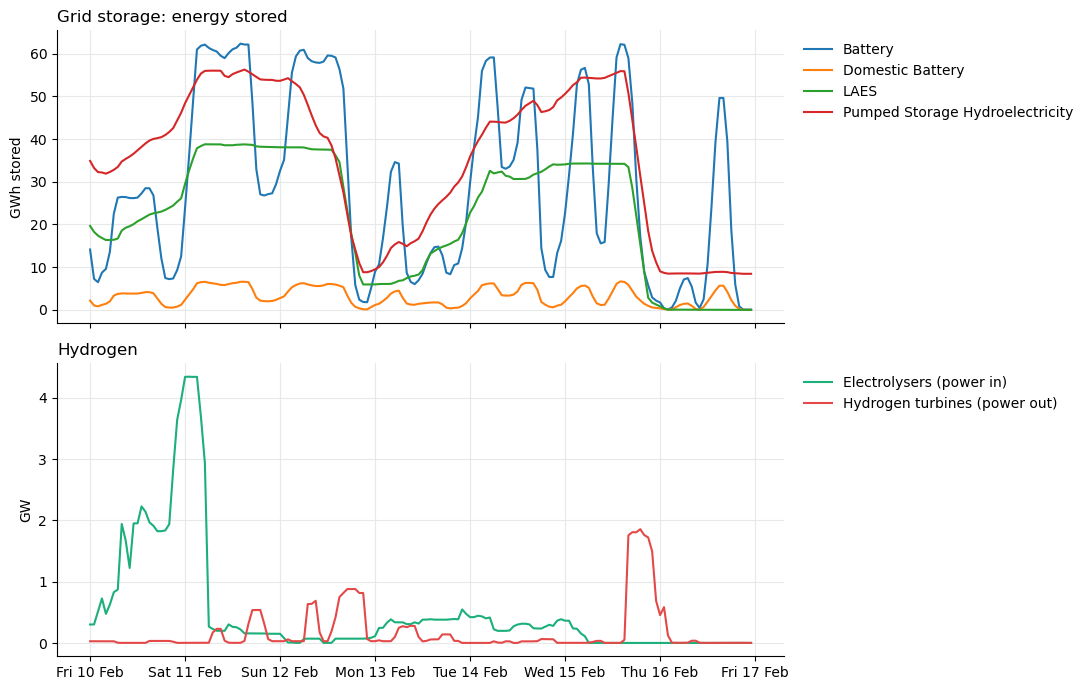

Electrolysers used 86 GWh of electricity; hydrogen turbines made 30 GWh


In [4]:
units = n40.storage_units[~n40.storage_units.carrier.isin(CONSUMER_FLEX)]
soc = n40.storage_units_t.state_of_charge[units.index].T.groupby(units.carrier).sum().T / 1e3

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for carrier in soc.columns:
    ax1.plot(soc.index, soc[carrier], lw=1.5, label=carrier)
ax1.set_ylabel("GWh stored")
ax1.set_title("Grid storage: energy stored", loc="left")
ax1.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))

electrolysis = series(n40, "links", "p0", n40.links.index[n40.links.carrier == "electrolysis"]).sum(axis=1) / 1e3
turbines = link_output(n40, n40.links.index[n40.links.carrier == "H2_turbine"]).sum(axis=1) / 1e3
ax2.plot(electrolysis.index, electrolysis, color="#1baf7a", lw=1.5, label="Electrolysers (power in)")
ax2.plot(turbines.index, turbines, color="#e34948", lw=1.5, label="Hydrogen turbines (power out)")
ax2.set_ylabel("GW")
ax2.set_title("Hydrogen", loc="left")
ax2.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
day_axis(ax2)
plt.tight_layout()
plt.show()

print(f"Electrolysers used {electrolysis.sum():,.0f} GWh of electricity; hydrogen turbines made {turbines.sum():,.0f} GWh")

Batteries cycle every day, filling overnight and around midday and emptying into the evening peaks. Pumped hydro and
liquid-air storage (LAES) fill over the windy days and empty when the wind drops, on 13 and 16 February. Electrolysers
run when power is cheapest, early in the week, and the hydrogen turbines run only on the calm evening of 15 February.
Over one week hydrogen is a small part of the system: its role is to carry energy between seasons, which a single
week cannot show.

## Unused wind and solar, and prices

,available,used,"unused, %"
carrier,,,
solar_pv,756.7,754.3,0.3
wind_offshore,5569.6,4815.9,13.5
wind_onshore,2363.7,2179.9,7.8


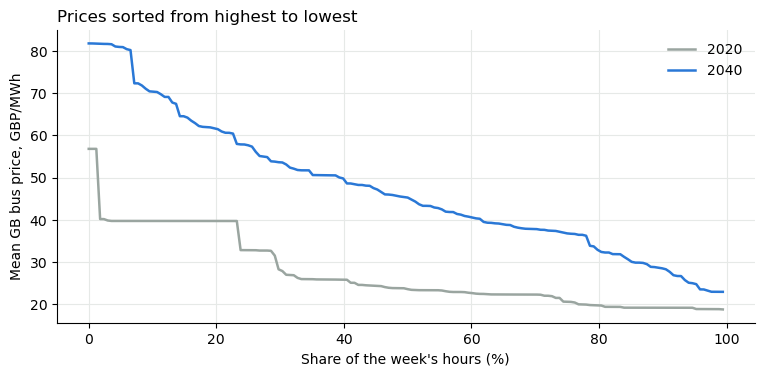

In [5]:
def curtailment(n):
    vre = n.generators.index[n.generators.carrier.isin(["wind_onshore", "wind_offshore", "solar_pv"])
                             & n.generators.bus.isin(gb_buses(n))]
    available = (n.generators_t.p_max_pu.reindex(columns=vre, fill_value=1.0) * n.generators.p_nom[vre]).sum()
    used = n.generators_t.p[vre].sum()
    by = pd.DataFrame({"available": available, "used": used}).groupby(n.generators.carrier[vre]).sum() / 1e3
    by["unused, %"] = 100 * (1 - by.used / by.available)
    return by.round(1)


display(curtailment(n40))

fig, ax = plt.subplots(figsize=(9, 3.8))
for year, n in runs.items():
    mean_price = n.buses_t.marginal_price[gb_buses(n)].mean(axis=1).sort_values(ascending=False).values
    ax.plot(100 * pd.Series(range(len(mean_price))) / len(mean_price), mean_price, lw=1.8, label=year,
            color={"2020": "#9aa5a0", "2040": "#2a78d6"}[year])
ax.set_xlabel("Share of the week's hours (%)")
ax.set_ylabel("Mean GB bus price, GBP/MWh")
ax.set_title("Prices sorted from highest to lowest", loc="left")
ax.legend()
plt.show()

About one-seventh of the offshore wind goes unused, almost all of it on the two windy spells (10 and 11 February,
13 and 14 February), when exports and storage are already full.
The mean GB price in 2040 ranges from about GBP 23 to 82/MWh, against GBP 19 to 57/MWh in the 2020 week. These are
means across GB buses: behind a full line, local prices fall much lower in the windy hours, as tutorial 1 showed for
2020. Fuel and carbon prices are the model's default central case (`marginal_costs.future_costs.case`).

## Where the network binds in 2040

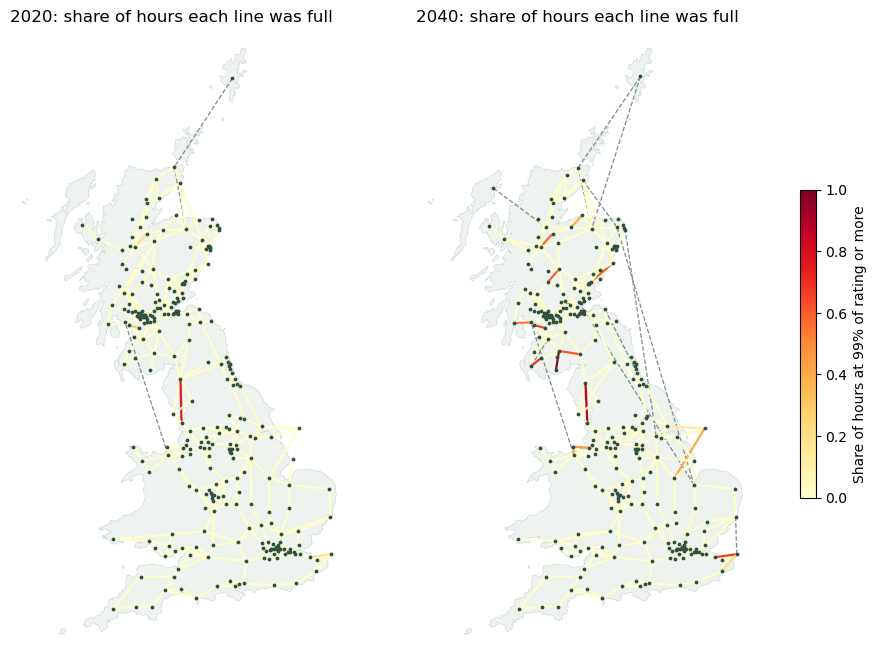

In [6]:
fig, axes = plt.subplots(1, len(runs), figsize=(6 * len(runs), 8))
axes = list(axes) if len(runs) > 1 else [axes]
for ax, (year, n) in zip(axes, runs.items()):
    loading = n.lines_t.p0.abs() / (n.lines.s_nom * n.lines.s_max_pu)
    lc = network_map(ax, n, (loading >= 0.99).mean(), cmap="YlOrRd", bus_size=3,
                     title=f"{year}: share of hours each line was full")
fig.colorbar(lc, ax=axes, shrink=0.5, label="Share of hours at 99% of rating or more")
plt.show()

In 2040 more lines are full, and more often: within Scotland, into North Wales, and where East Anglia's offshore wind
lands. The dashed lines are the HVDC links planned by 2040, including the Eastern Green Links down the east coast.
These are intact thermal limits only, in a single solve; the secured boundary limits of the two-stage market bind
harder ([tutorial 2](2-network-models.ipynb), [tutorial 5](5-two-stage-market-2030.ipynb)).

## Try it yourself

**Another pathway.** FES 2025 has three net-zero pathways, Holistic Transition (`HT`), Electric Engagement (`EE`) and
Hydrogen Evolution (`HE`), and a counterfactual that misses net zero, Falling Behind (`FB`). Change the pathway:

```yaml
My_2040_EE:
  inherits: Tutorial_2040_HT_clustered
  description: FES 2025 Electric Engagement 2040, the tutorial week
  targets: {source: FES, edition: 2025, pathway: EE}
```

**Another year.** Set `modelled_year: 2050` and a 2050 `solve_period`.

**Another weather year.** 2010 was a cold, low-wind year: set `renewables_year: 2010` and `demand_year: 2010`, and
compare the curtailment and prices.

Next: [tutorial 5](5-two-stage-market-2030.ipynb) runs the two-stage market on the 2030 system.